# Как разметка может стать основой тьютора

**Предварительное локальное исследование v2.** Проверяем не обучение учеников, а достаточность представления содержания: какие задачи и шаги можно переиспользовать и какие условия для этого теряются.

Главный вывод: **KC — полезный поисковый ключ, но недостаточная единица учебного взаимодействия.** Для проверяемого упражнения нужны ещё входное состояние, наблюдаемое преобразование, ожидаемый результат, ограничения и роль результата в исходной задаче. Часть этих сведений уже есть в трассах, часть требует явной редакторской подготовки.

[Интерактивное сопоставление условий и решений](index.html) · [Исполненный EDA-ноутбук](review.ipynb) · [Методика](PROTOCOL.md) · [Проверки](checks/final.json).


In [1]:
from pathlib import Path
import sys, json
from IPython.display import display, Image, HTML, Markdown
root=next(p for p in (Path.cwd(), *Path.cwd().parents) if (p/'scripts/build_tutor_bridge.py').exists())
sys.path.insert(0,str(root/'scripts'))
import build_tutor_bridge as bridge
bridge.build()
out=bridge.OUT
summary=bridge.read(out/'summary.json')
print('Без моделей и сети. Структурный анализ 100 разборов; основные показатели по 98; качественные контрасты 19 задач.')

Baseline and frozen inputs byte-identical.


{
  "task_n": 100,
  "included_n": 98,
  "qualitative_tasks": 19,
  "linear_contracts": 12,
  "same_kc_pairs": 66,
  "same_coarse_route_pairs": 5,
  "prior_step_ready": 8,
  "within_step_preparation": 4,
  "focal_steps_with_multiple_candidates": 7,
  "component_not_final_quantity": 3,
  "qualitative_pairs": 9,
  "qualitative_single_cases": 2,
  "structural": [
    {
      "layer": "historical_editorial",
      "tasks": 49,
      "steps": 156,
      "steps_with_multiple_candidates": 53,
      "tasks_with_multiple_methods": 5,
      "steps_with_any_unmapped_candidate": 0
    },
    {
      "layer": "audited_new",
      "tasks": 49,
      "steps": 183,
      "steps_with_multiple_candidates": 27,
      "tasks_with_multiple_methods": 8,
      "steps_with_any_unmapped_candidate": 109
    }
  ]
}
Без моделей и сети. Структурный анализ 100 разборов; основные показатели по 98; качественные контрасты 19 задач.


## 1. Что проверили

Сохранённые 100 разборов, основные показатели по прежним 98. Для всех 12 принятых применений линейного уравнения выписаны отдельные контракты действия. Девять пар и два одиночных случая выбраны целенаправленно после просмотра для контрастов. Это исследование представления, не случайная выборка для оценки распространённости и не независимая экспертная оценка.

Фактический порядок: сначала просмотр исходников и подготовка смысловых входов, затем полный расчёт и целевой браузерный просмотр. Запланированный визуальный пилот 2–3 контрастов не был отдельным шлюзом перед полной обработкой; это отмечено в [журнале метода](checks/method-review.json). Работа исследовательская, не ослеплённая проверка.

Утверждения разных типов разделены: исходные поля с точными цитатами; интерпретации основного ассистента; ограниченные математические проверки; гипотезы дизайна. Нормализованные уравнения и контексты — отдельный редактируемый вход, а не результат автоматического парсинга. Любое новое предметное толкование требует просмотра.


## 2. Что общий KC скрывает

У 12 задач получается 66 возможных пар по одному общему KC. Только 5 пар относятся к одной из наших грубых групп подготовки; сама группировка исследовательская и не означает совпадения полного метода. Это не означает, что остальные пары плохие: им может соответствовать практика переноса, но они добавляют другое содержание.

| Слой (по 49 включённых задач) | Шагов | Шагов с несколькими кандидатами | Шагов с неназначенным кандидатом |
|---|---:|---:|---:|
| Исторические редакторские связи | 156 | 53 | 0 |
| Независимые агентные назначения | 183 | 27 | 109 |

Число Method может означать разные пункты с общими шагами, а не альтернативные способы. Совместное присутствие KC в шаге не устанавливает, какой из них вызвал бы ошибку ученика.

В 8/12 случаев аффинный вход явно установлен предшествующим шагом; в 4/12 требуется подготовка внутри шага с назначенным KC (подстановка, квадрат или сокращение квадратных членов). В 7/12 фокусных шагов указано несколько кандидатов. В 3/12 результат линейного компонента не является спрашиваемой величиной всей задачи.

Числа описывают эти записи и новую явную рубрику; не измеряют трудность или владение навыком.



### Контракты всех 12 действий

| ID | Вход для компонента (редакторская запись) | Значение компонента | Что требуется после / дополнительно |
|---|---|---|---|
| 19FBCF | `x+6=4*x` | 2 | Проверить исходное показательное равенство |
| B948D4 | `x-7=-3` | 4 | Проверить исходное показательное равенство |
| 517970 | `x-2=11` | 13 | Сохранить x>2 |
| 91CD43 | `8-x=2` | 6 | Сохранить x<8; проверка допустимости отдельным кандидатом не назначена |
| 7D21DC | `x+3=2*x` | 3 | Искомая величина — абсцисса; ордината 6 не является ответом |
| 6D1598 | `N/20=6` | 120 | N — положительное целое число участников |
| D334F2 | `1476*x=110700000` | 75000 | 75000 — платёж; требуется сумма 4 платежей = 300000 |
| D6F31D | `10*c=3150` | 315 | c>0, c≠11; сверить частоту и единицы |
| 8B91B1 | `(1331/1000)*S-(331/100)*(S+40980)/3=0` | 198600 | Сумма кредита S, а не платёж; проверить промежуточные остатки |
| EA6D9D | `(1331/1000)*(3*x-34150)-(331/100)*x=0` | 66550 | 66550 — платёж; ответ задачи 3x=199650; проверка остатков |
| F2A2EB | `(5-e)**2=e**2-e+1` | 8/3 | e=AE — промежуточная длина; ответ задачи 4/9 |
| c15c1c | `14400=(3/5)*a` | 24000 | a≥0; проверить исходный корень и единицы |

В F2A2EB исходное равенство выглядит квадратным: (5−e)²=e²−e+1, но квадратные члены сокращаются и остаётся −9e+24=0. В c15c1c сначала нужно обосновать возведение в квадрат. Поэтому простой поиск «в шаге есть linear_equation» ещё не даёт готового одинакового входа для упражнения.


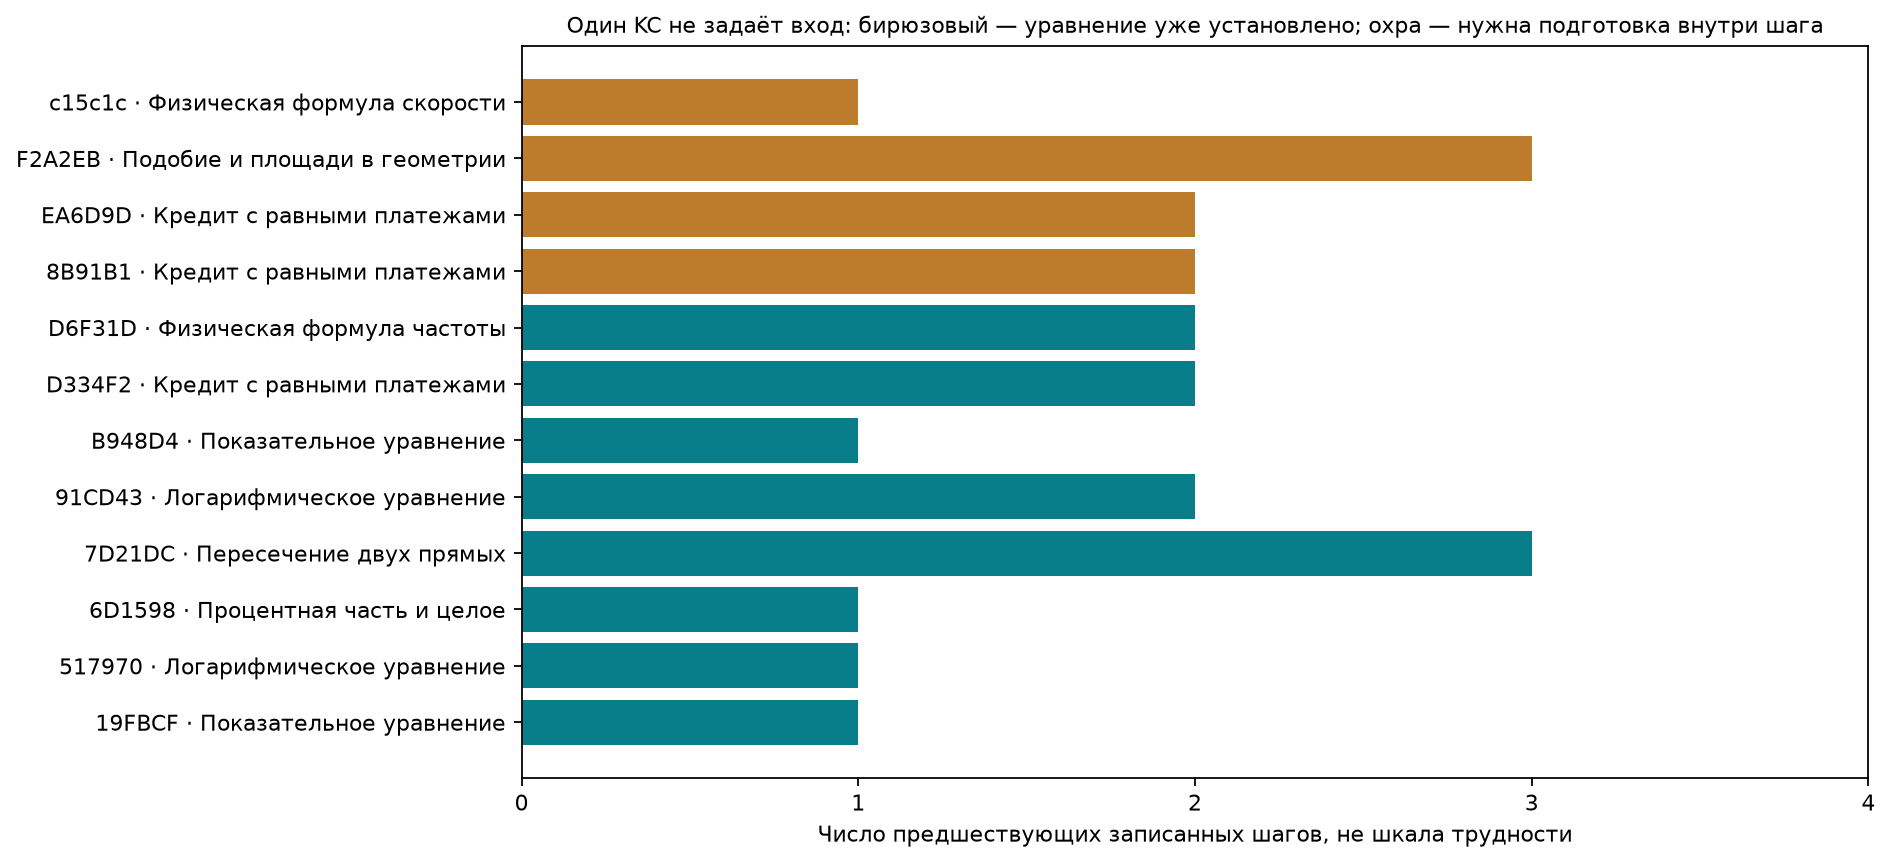

In [2]:
display(Image(filename=str(out / 'figures/entry-work.png')))

## 3. Содержательные сопоставления

### P01. Близкий маршрут: две показательные задачи

**Наблюдение:** Обе трассы приводят основание к одному виду и затем решают линейное уравнение. Различаются преобразование основания и коэффициенты; это более узкое основание сходства, чем общий KC.

**Возможное применение:** Кандидаты для повторения одного маршрута; после предметной проверки можно менять числовую форму, сохраняя общий план.

**Граница:** Одинаковая запись метода и верные решения не доказывают освоение или перенос. Пара выбрана после просмотра.

### P02. Общее действие, разные условия входа

**Наблюдение:** В первом случае получено x+6=4x; во втором 8−x=2 при x<8. Общий линейный фрагмент не включает ни приведение степеней, ни закон логарифма и ОДЗ.

**Возможное применение:** Для практики только линейной операции можно дать установленное уравнение; полная логарифмическая задача добавляет другое содержание.

**Граница:** Нельзя автоматически назначать любую задачу с этим KC ученику, испытывающему затруднение в линейном уравнении.

### P03. Ответ компонента не равен ответу задачи

**Наблюдение:** В 19FBCF x=2 завершает задачу. В D334F2 x=75000 — только ежегодный платёж; требуется 4x=300000. До линейной операции надо построить и раскрыть модель долга.

**Возможное применение:** Хранить отдельно цель текущего шага и цель всей задачи. Проверка платежа не должна засчитывать ответ на вопрос об общей сумме.

**Граница:** Выбор следующей помощи по профилю ученика здесь не проверен; установлена разница выходных величин в источниках.

### P04. Близкие графические варианты, разная нарезка шагов

**Наблюдение:** Обе трассы восстанавливают k/x и прямую, приравнивают значения, получают квадратное уравнение и выбирают второй корень. В одном разборе решение и выбор точки записаны одним шагом, в другом двумя.

**Возможное применение:** Для маршрута можно хранить общую схему действий без требования одинакового числа шагов. Близкие варианты учитывать при будущем отделении проверки от разработки.

**Граница:** Это качественное сходство двух просмотренных трасс, не автоматически установленное семейство всего банка. Число шагов не шкала трудности.

### P05. Одинаковая цель по графику, другая алгебра

**Наблюдение:** Две прямые дают x+3=2x. Обратная пропорциональность и прямая дают 9/x=x/3−2 и x²−6x−27=0, после чего ещё нужно выбрать вторую точку.

**Возможное применение:** При подборе полного задания учитывать форму функций, уравнение после моделирования и то, какую координату спрашивают; метки «график» недостаточно.

**Граница:** Более длинный маршрут не устанавливает объективную трудность; требуется проверить оба рисунка и решения.

### P06. Одинаковый кредитный сюжет, разные неизвестные и итог

**Наблюдение:** Обе модели используют 10% и три равных платежа. В 8B91B1 ищут исходный кредит S; в EA6D9D — общую сумму выплат 3x. Последний разбор совмещает подстановку, решение и интерпретацию в s3.

**Возможное применение:** Определять цель по спрашиваемой величине, а не по сюжету или имени переменной; сохранять содержательные поддействия даже внутри одного шага.

**Граница:** Различия разметки и выбора переменной не означают разную способность ученика; ни одна переменная не обязательна для правильного решения.

### P07. Один рациональный приём, разные последующие задачи

**Наблюдение:** Устранение знаменателя в физической формуле даёт 10c=3150, в графическом пересечении — квадратное уравнение. Ограничения c≠11 и x≠0 сохраняются, но последующая операция различается.

**Возможное применение:** Фильтр по преобразованию рационального уравнения должен различать практику самого преобразования и весь последующий метод.

**Граница:** Совместный KC не означает взаимозаменяемость полных задач; численная проверка не проверяет чтение рисунка.

### P08. Знакомая часть составного кандидата не даёт полного назначения

**Наблюдение:** В 68Ac00 шаг s4 содержит x(x−5)=0, получение корней и выбор B. В 87FAA1 s5 решает факторизованное уравнение, s6 выбирает точку, но сам кандидат факторизации остаётся составным для узкого zero_product.

**Возможное применение:** Не использовать отсутствие match как доказательство отсутствия действия. Сохранять наблюдаемую операцию, её контекст и отдельную неопределённость назначения.

**Граница:** Мы не переназначаем исходные KC и не объявляем нужную атомизацию найденной: это вопрос уровня учебного действия.

### P09. Почти одинаковое условие, разный порог допуска аудита

**Наблюдение:** Условия различаются вероятностью попадания, но оба задают только отдельные вероятности выстрелов. Произведение использует независимость; один аудит блокирует это допущение, другой принимает оговорённую модель.

**Возможное применение:** Хранить модельное предположение и политику допуска отдельно от результата вычисления. До использования эталона согласовать единый порог.

**Граница:** При заданных только маргинальных вероятностях существует зависимая модель с другой вероятностью события. Это не утверждение об ошибке официальной экзаменационной конвенции.

### S01. Ноль принятых связей не означает отсутствие математики

**Наблюдение:** Разбор использует cos(2α)=1−2sin²α и вычисляет 2,76. Ни один из двух кандидатов не имеет match: один спорен из-за перекрытия определений, другой предложен как новая арифметическая операция.

**Возможное применение:** В поиске материалов хранить исходные действия и причины неназначенности; каталог — дополнительный слой. Пустая проекция на каталог не должна превращаться в пустое решение.

**Граница:** Корректность данной формулы и арифметики не устанавливает педагогическую ценность выделения умножения в отдельный KC.

### S02. Общий текст без рисунков теряет условия

**Наблюдение:** В этой задаче обозначения и AM=BN=3 находятся в изображениях. Первое чтение как 1 пропустил и аудитор; активная исправленная трасса имеет происхождение source_reading_feedback.

**Возможное применение:** Учебный материал должен включать изображения и происхождение чтения; перед допуском проверять источник отдельно от логики решения.

**Граница:** Активное решение не является независимым повтором, а согласие двух агентов не устанавливает предметную правильность.

Все условия, нужные шаги и решения аудитора доступны рядом в HTML. Доказательные поля сохранены в evidence.json с JSON Pointer и SHA-256. Сходство полного маршрута — интерпретация этих случаев, не измеренная взаимозаменяемость упражнений.


In [3]:
from lxml import html as dom
tree=dom.fromstring((out/'index.html').read_text(encoding='utf-8'))
for case_id in ['P02','P03','P04']:
    panel=tree.get_element_by_id(case_id)
    # HTML snapshots in the notebook carry the same original formulas/images.
    # Rewrite relative source image URLs for this notebook's identical folder.
    panel.set('open','open')
    display(HTML(dom.tostring(panel,encoding='unicode')))

## 4. Минимальный исполнимый мост

Мы сделали узкую офлайн-демонстрацию: **сохранённая трасса → редакторский контракт → нормализованное аффинное уравнение → точная проверка числового ответа**. Для всех 12 уравнений коэффициенты вычислены рационально, квадратные члены при необходимости сокращены, проверена единственность корня и согласованность указанного значения.

60 искусственных программных проб проверяют ожидаемый числовой результат, заведомо другое число и неподдерживаемые форматы. Это тест программного поведения, не accuracy тьютора и не попытки учеников. Проверка не принимает свободное решение, не объясняет причину ошибки, не проверяет все ограничения модели и не засчитывает всю исходную задачу. Для любого уравнения принимается один точный числовой ответ; неподдерживаемый формат вызывает уточнение.

Например, 75000 удовлетворяет компонентному уравнению D334F2, но исходный вопрос требует 300000. Такой результат показывает необходимость отдельного поля «что сейчас проверяем», иначе компонентный успех превратится в ложное принятие полного ответа.

### Три контентных запроса

Q1: Поиск всех принятых применений линейного уравнения → 12 задач: 19FBCF, 517970, 6D1598, 7D21DC, 8B91B1, 91CD43, B948D4, D334F2, D6F31D, EA6D9D, F2A2EB, c15c1c

Q2: Требовать явный аффинный вход в предыдущем шаге → 8 задач: 19FBCF, 517970, 6D1598, 7D21DC, 91CD43, B948D4, D334F2, D6F31D

Q3: Сузить полный маршрут до показательного семейства → 2 задач: 19FBCF, B948D4



Это работающий фильтр по подготовленным описаниям, а не обученная рекомендательная политика. Q2 и Q3 независимы. Логарифмическая задача не превращается в чистую линейную только из-за наличия KC; можно выделить подготовленный фрагмент, но это уже отдельное упражнение с явно данным состоянием.


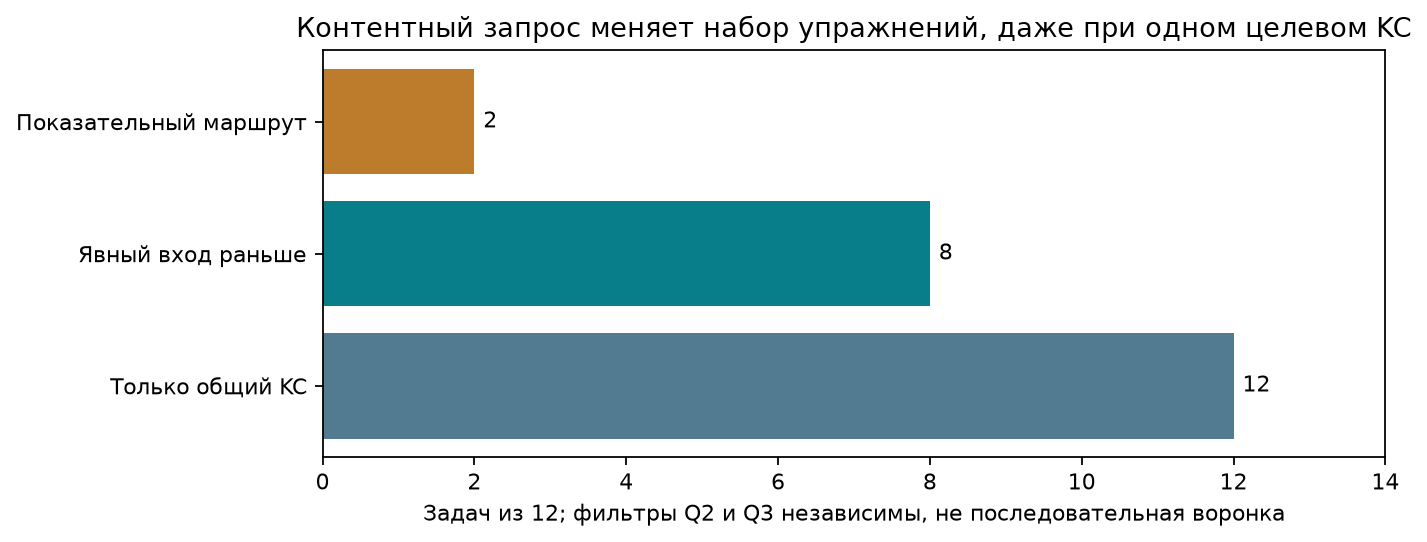

In [4]:
display(Image(filename=str(out / 'figures/content-queries.png')))

In [5]:
contracts=bridge.read(out/'derived-contracts.json')
c=next(c for c in contracts if c['task_id']=='D334F2')
for value in ['75000','300000','x=75000']:
    print(value, bridge.check_component(c,value))
print('Искусственные программные примеры: 75000 — ответ компонента; полный вопрос требует 300000.')

75000 {'status': 'satisfies_equation', 'residual': '0', 'scope': 'Только данное уравнение; не диагноз, не полнота решения и не вся задача'}
300000 {'status': 'does_not_satisfy_equation', 'residual': '332100000', 'scope': 'Только данное уравнение; не диагноз, не полнота решения и не вся задача'}
x=75000 {'status': 'clarification', 'reason': 'Формат вне узкой грамматики: нужен один числовой ответ без единиц и объяснения'}
Искусственные программные примеры: 75000 — ответ компонента; полный вопрос требует 300000.


## 5. Что говорят ограничения и контрпримеры

| Сопоставление | Jaccard принятых KC | Что надо учитывать сверх числа |
|---|---:|---|
| 19FBCF/B948D4 | 1.000 | Близкий маршрут: две показательные задачи |
| 02A17e/87FAA1 | 1.000 | Близкие графические варианты, разная нарезка шагов |
| 7D21DC/02A17e | 0.600 | Одинаковая цель по графику, другая алгебра |
| 8B91B1/EA6D9D | 0.667 | Одинаковый кредитный сюжет, разные неизвестные и итог |
| C41083/F3F0DF | 0.000 | Почти одинаковое условие, разный порог допуска аудита |

В таблице Jaccard — размер пересечения принятых множеств KC, делённый на размер их объединения. Это описание сохранённой проекции, не метрика качества рекомендаций. Для C41083/F3F0DF сравниваются обе сохранённые записи, включая исключённую из основных частот; ноль возникает при близких условиях и разной политике допуска. Для 02A17e/87FAA1 единица не означает полноту описания: факторизация и выбор точки остаются без полных назначений. Так проверяется конкретная потеря информации при переходе от решения к набору принятых KC.

Пары C41083/F3F0DF показывают разный порог принятия одного модельного допущения. Независимые выстрелы дают p(1−p)³; если все четыре исхода равны одной бернуллиевской переменной с тем же p, событие «попадание, затем три промаха» невозможно. Обе модели имеют одинаковые отдельные вероятности выстрелов. Значит, одних маргинальных вероятностей недостаточно; экзаменационная конвенция должна быть отдельным правилом допуска, а не незаметной частью эталона. Мы не объявляем официальное задание ошибочным.

В F6158A ни у одного из двух кандидатов нет принятой связи, но формула и арифметика дают 3(1−2·0,2²)=2,76. Нулевая проекция на каталог не означает отсутствия действия. В 68Ac00 знакомая операция входит в составной кандидат и не получает узкого match. Следовательно, для поиска материалов нужны и исходные действия, и назначения, и причины неопределённости.

F416AF показывает отдельный разрыв: ошибка чтения картинки может пройти автора и аудитора. Происхождение источника, проверка математики и KC-сопоставление — разные проверки. Полнота каталога не заменяет ни одну из них.


## 6. Карта от данных к функциям тьютора

| Что есть / проверено | Какой ограниченный шаг можно сделать | Чего ещё нет |
|---|---|---|
| ID задач, принятые KC, исходные условия | Получать кандидатов для практики заданного действия | Предметного допуска и доказанной подходящести конкретному ученику |
| Шаги, результаты, input_refs + явные контракты | Подготовить вход, цель и результат компонентного упражнения | Универсального автоматического извлечения таких контрактов |
| 12 выписанных уравнений, точная арифметика | Проверять один числовой ответ к данному аффинному состоянию | Проверки свободного метода, источника и полного решения |
| Различия входа и последующей интерпретации | Разделять тренировку операции и полного маршрута | Проверенных диагностических вопросов и причин ошибок |
| Источник, версии и замечания аудитора | Сохранять условия допуска и неопределённость материала | Единой предметной рубрики допуска всех эталонов |
| Попыток учеников нет | Спроектировать журнал наблюдений, пока без оценок освоения | Эмпирического профиля, правила помощи, критерия освоения и образовательного эффекта |

### Предлагаемая единица содержания

`source_task + source_version + target_action + established_input_state + relevant_conditions + requested_output + accepted_variants + validation_scope + evidence + review_status`.

Это предложение схемы, а не миграция исходной разметки. Статус «правильный числовой ответ к подготовленному уравнению» не равен «самостоятельно решил задачу» или «освоил KC». Связь с профилем возникает только после реальной попытки, с сохранением помощи и контекста.


## 7. Какое решение оправдано теперь

**Можно переходить к проектированию маленького содержательного цикла**, опираясь на конкретный подготовленный контракт. Сначала отдельно проверить условие, математику и цель упражнения; затем определить допустимые ответы и границу отказа. Для компонентного режима вход даётся явно; для полного маршрута ученик должен сам его получить. Эти режимы нельзя смешивать в метриках успеха.

До живой диагностики: сформировать независимый предметно проверенный набор правильных, ошибочных и неоднозначных ответов, заморозить критерии до испытания, проверить ложное принятие и запросы уточнения. Примеры из этой работы — разработка, не отложенный тест. Далее нужны реальные попытки и отдельная проверка переноса. Никакая их результативность здесь не измерена.


## 8. Связь с прежними исследованиями и воспроизведение

В [опыте входного состояния](../../../../research/2026-10-27-map-context-transfer/README.md) контекст менял свидетельство применимости одного известного действия, но не устанавливал освоение. Здесь то же требование проявляется на конкретных материалах: текущий шаг нужно связывать с уже установленным состоянием. [Исследование границ KC](../../../../research/2026-10-27-kc-investigation/README.md) рекомендовало сохранять операции и контрпримеры; составные случаи подтверждают необходимость этого для представления содержания, а не правильность окончательных границ навыков. Старые исследования не являются независимой проверкой новой версии.

Команда: `.venv/Scripts/python.exe -B -X utf8 scripts/build_tutor_bridge.py` из корня. Она пересчитывает сохранённые данные и программные проверки без сети/моделей. Исполненный ноутбук строится и проверяется `scripts/finalize_tutor_bridge.py`; зависимости и SHA-256 фиксируются в provenance.json. Новые смысловые входы — component-contracts.json и case-interpretations.json. Их автоматическое воспроизведение без редакторского суждения не обещается.

Сохранены точные входы, цитаты и хеши; старые ответы/каталоги/EDA/v1 не меняются. Полная математическая экспертиза всех 100, реальные ученики и эффективность тьютора остаются вне проверки. Всё локально, без commit/push.
